# Local walkthrough: input, process and output of every step

This notebook reruns the analysis on your laptop one step at a time. Each step has three parts:

- **Input:** what goes in, shown with real values
- **Process:** what the code does, and which repo file does it
- **Output:** what comes out, with shapes, examples and a check

Everything runs on a CPU except AgroNT itself (a 1B-parameter model needs a GPU). Step 3b therefore
**loads the AgroNT embeddings you computed on Colab**. Before running, download the
`pgb_embeddings/agront-1b` folder from Google Drive and put it in this repo as `data/embeddings/agront-1b/`.

Run the cells top to bottom (Shift+Enter). The whole notebook takes a few minutes.

## Setup

In [2]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pgb, kmers, evaluate, embed   # the repo's own modules

SPECIES   = "arabidopsis_thaliana"
MAX_TRAIN = 5000          # must match the Colab run, so the embeddings line up with the same genes
SEED      = 2026
MODEL     = "agront-1b"

DATA_DIR = Path(os.environ.get("PGB_DATA_DIR", ROOT / "data" / "raw"))
EMB_DIR  = Path(os.environ.get("PGB_EMB_DIR", ROOT / "data" / "pgb_embeddings")) / MODEL
TAG      = f"{SPECIES}_train{MAX_TRAIN}"
OUT_DIR  = ROOT / "results" / "walkthrough"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repo:       ", ROOT)
print("Data:       ", DATA_DIR, "| found" if DATA_DIR.exists() else "| MISSING: run scripts/download_data.py")
print("Embeddings: ", EMB_DIR, "| found" if EMB_DIR.exists() else "| MISSING: download agront-1b from Google Drive")

Repo:        C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression
Data:        C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\data\raw | found
Embeddings:  C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\data\pgb_embeddings\agront-1b | found


## Step 1. Read the benchmark files

**Input:** three FASTA files (train, validation, test) from the Plants Genomic Benchmark.
Each record is one gene: a header line `>GENE_ID|value_1|...|value_56` and its 6,000 bp sequence.

**Process:** `src/pgb.py`. `local_files` finds the three files; `parse_header` splits a header on `|`;
`read_fasta` joins sequence lines, upper-cases bases and checks every gene has the same number of values.

In [3]:
files = pgb.local_files(SPECIES, DATA_DIR)
for split, path in files.items():
    print(f"{split:5s}  {path.name:40s} {path.stat().st_size / 1e6:7.1f} MB")

print("\nThe raw input: first two records of the training file (truncated)")
with pgb._open(files["train"]) as fh:
    records, seq_line_shown = 0, False
    for line in fh:
        line = line.rstrip()
        if line.startswith(">"):
            if records == 2:
                break
            records += 1
            seq_line_shown = False
            print(line[:110] + (" ..." if len(line) > 110 else ""))
        elif not seq_line_shown:
            print("   " + line[:80] + " ...")
            seq_line_shown = True

train  arabidopsis_thaliana_train.fa              174.7 MB
valid  arabidopsis_thaliana_validation.fa          23.1 MB
test   arabidopsis_thaliana_test.fa                23.1 MB

The raw input: first two records of the training file (truncated)
>AT1G01020|8.113895660778276|7.892966247814842|7.2572027234602015|8.912964676913413|8.911928631902894|9.106527 ...
   GAAAAAATGTGCATTTGTTTTCTGGTAAATACATATAGGTTAGAGGAGGAAAAAAGAAAAAAATACATATAGAGGTTAGT ...
>AT1G01040|11.003653830620282|11.32701467949556|10.225230850438049|10.570588889688551|10.519885234041821|10.46 ...
   TCACATACACACCTATCAAAAACTTAAAACCTTTCAAAACCTCTTGGTATATTCAAATTAGGATTCTTCATTCATGGAAT ...


In [4]:
# How one header is parsed
first_header = next(l for l in pgb._open(files["train"]) if l.startswith(">"))[1:].strip()
gene_id, values = pgb.parse_header(first_header)
print("gene id:         ", gene_id)
print("number of values:", len(values), "(one per tissue / condition)")
print("first 5 values:  ", [round(v, 2) for v in values[:5]])

gene id:          AT1G01020
number of values: 56 (one per tissue / condition)
first 5 values:   [8.11, 7.89, 7.26, 8.91, 8.91]


**Output:** one `Split` object per file, holding gene IDs, sequences and a genes × 56 expression matrix.

In [5]:
full = {split: pgb.read_fasta(path) for split, path in files.items()}
summary = pd.DataFrame({
    split: {"genes": len(d), "outputs per gene": d.y.shape[1],
            "min length": min(map(len, d.seqs)), "max length": max(map(len, d.seqs)),
            "genes containing N": sum("N" in s for s in d.seqs)}
    for split, d in full.items()}).T
display(summary)

y_preview = pd.DataFrame(full["train"].y[:5, :6], index=full["train"].ids[:5],
                         columns=[f"tissue_{j+1}" for j in range(6)]).round(2)
print("The target matrix y (first 5 genes, first 6 of 56 tissues):")
display(y_preview)

,genes,outputs per gene,min length,max length,genes containing N
train,25731,56,6000,6000,35
valid,3401,56,6000,6000,3
test,3402,56,6000,6000,4


The target matrix y (first 5 genes, first 6 of 56 tissues):


,tissue_1,tissue_2,tissue_3,tissue_4,tissue_5,tissue_6
AT1G01020,8.11,7.89,7.26,8.91,8.91,9.11
AT1G01040,11.00,11.33,10.23,10.57,10.52,10.47
AT1G01046,3.47,3.65,1.14,3.22,2.05,2.30
AT1G01050,10.96,10.94,11.07,10.65,10.62,10.49
AT1G01070,9.70,9.99,9.33,4.07,4.00,1.36


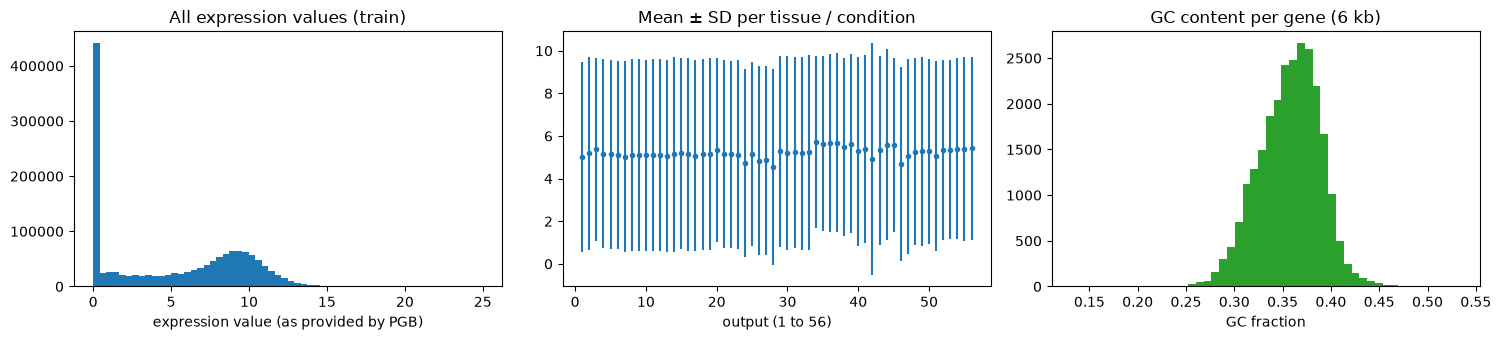

Expression values range 0.00 to 24.98; median GC content 0.360


In [6]:
y = full["train"].y
gc = np.array([(s.count("G") + s.count("C")) / len(s) for s in full["train"].seqs])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(y.ravel(), bins=60, color="tab:blue"); ax[0].set_title("All expression values (train)")
ax[0].set_xlabel("expression value (as provided by PGB)")
ax[1].errorbar(np.arange(1, y.shape[1] + 1), y.mean(0), yerr=y.std(0), fmt="o", ms=3)
ax[1].set_title("Mean ± SD per tissue / condition"); ax[1].set_xlabel("output (1 to 56)")
ax[2].hist(gc, bins=50, color="tab:green"); ax[2].set_title("GC content per gene (6 kb)")
ax[2].set_xlabel("GC fraction")
plt.tight_layout(); plt.show()
print(f"Expression values range {y.min():.2f} to {y.max():.2f}; median GC content {np.median(gc):.3f}")

## Step 2. Fix the training subset

**Input:** the 25,731 training genes, a subset size (5,000) and a seed (2026).

**Process:** `pgb.subsample_indices` draws 5,000 gene positions at random with that seed. The same seed always
gives the same genes, on any computer. Validation and test are never subsampled.

**Output:** the task used by every model: 5,000 train, 3,401 validation and 3,402 test genes.

In [7]:
idx = pgb.subsample_indices(len(full["train"]), MAX_TRAIN, SEED)
assert np.array_equal(idx, pgb.subsample_indices(len(full["train"]), MAX_TRAIN, SEED)), "not deterministic"
task = pgb.load_task(SPECIES, DATA_DIR, MAX_TRAIN, SEED)

print("First 5 chosen genes:", task["train"].ids[:5])
print({split: len(d) for split, d in task.items()})
print(f"Mean expression, full train: {full['train'].y.mean():.3f} | subset: {task['train'].y.mean():.3f} "
      "(similar, so the subset is representative)")

First 5 chosen genes: ['AT1G01360', 'AT1G01420', 'AT1G01430', 'AT1G01500', 'AT1G01530']
{'train': 5000, 'valid': 3401, 'test': 3402}
Mean expression, full train: 5.215 | subset: 5.239 (similar, so the subset is representative)


## Step 3a. k-mer features (the baseline)

**Input:** the 6,000 bp sequence of each gene.

**Process:** `src/kmers.py`. Bases become numbers (A=0, C=1, G=2, T=3). A window of k bases slides along the
sequence; each window is read as a base-4 number that indexes one of 4^k k-mers. Counts are divided by the total,
giving frequencies. Windows with N are skipped. First, one gene:

In [8]:
K = 6
gene_seq, gene_name = task["train"].seqs[0], task["train"].ids[0]
freq = kmers.kmer_frequencies(gene_seq, K)
names = kmers.kmer_names(K)
n_windows = len(gene_seq) - K + 1

top = pd.DataFrame({"k-mer": names, "frequency": freq, "approx. count": np.round(freq * n_windows).astype(int)})
print(f"Gene {gene_name}: a vector of {len(freq)} frequencies that sums to {freq.sum():.3f}")
display(top.sort_values("frequency", ascending=False).head(8).reset_index(drop=True))

for motif, label in [("TATAAA", "TATA box"), ("CACGTG", "G-box"), ("GCCGCC", "GCC box")]:
    print(f"{label:9s} {motif}: {round(freq[names.index(motif)] * n_windows)} copies in this gene")

Gene AT1G01360: a vector of 4096 frequencies that sums to 1.000


,k-mer,frequency,approx. count
0,TTGTTT,0.003503,21
1,TTTGTT,0.003336,20
2,TTTTGT,0.003336,20
3,TTTTTT,0.003336,20
4,TGTTTT,0.002836,17
5,GAAGAA,0.002168,13
6,GAGAAA,0.001835,11
7,GAGAGA,0.001835,11


TATA box  TATAAA: 5 copies in this gene
G-box     CACGTG: 1 copies in this gene
GCC box   GCCGCC: 0 copies in this gene


**Output:** a genes × 4,096 matrix per split (k = 6). Every gene becomes a row of 6-mer frequencies.

In [9]:
t0 = time.time()
X_kmer = {split: kmers.kmer_matrix(d.seqs, (K,)) for split, d in task.items()}
print(f"Built in {time.time() - t0:.1f} s")
for split, X in X_kmer.items():
    print(f"{split:5s} {X.shape}  {X.nbytes / 1e6:.0f} MB")

Built in 4.8 s
train (5000, 4096)  82 MB
valid (3401, 4096)  56 MB
test  (3402, 4096)  56 MB


In [10]:
# A quick biology check: do single motifs track average expression on their own?
mean_expr = task["train"].y.mean(axis=1)
for motif, label in [("TATAAA", "TATA box"), ("CACGTG", "G-box"), ("GCCGCC", "GCC box")]:
    col = X_kmer["train"][:, names.index(motif)]
    rho = spearmanr(col, mean_expr)[0]
    print(f"{label:9s} frequency vs mean expression: Spearman rho = {rho:+.3f}")
print("Each motif alone explains only part of the variation; the ridge model in Step 4 combines all 4,096 k-mers.")

TATA box  frequency vs mean expression: Spearman rho = -0.055
G-box     frequency vs mean expression: Spearman rho = +0.050
GCC box   frequency vs mean expression: Spearman rho = +0.058
Each motif alone explains only part of the variation; the ridge model in Step 4 combines all 4,096 k-mers.


## Step 3b. AgroNT embeddings (the language model)

**Input:** the same sequences. AgroNT first cuts each one into 6-letter tokens.

**Process (on Colab):** `src/embed.py`. Tokens go through AgroNT's transformer layers; the last layer gives a
1,500-number vector for every token; these are averaged over the gene's tokens (padding ignored) into one
1,500-number vector per gene. The model is frozen: nothing is trained.

The next cell shows the tokenization step. It needs the `transformers` package
(`pip install transformers`) and downloads only the small tokenizer, not the model.

In [11]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(embed.MODELS[MODEL].repo)
    clean = task["train"].seqs[0]
    print("First 36 bp:         ", clean[:36])
    print("Its tokens:          ", tok.tokenize(clean[:36]))
    print("Tokens for 6,000 bp: ", len(tok(clean)["input_ids"]), "(about 1,000 six-mers + a start token)")
    with_n = clean[:30] + "N" + clean[31:36]
    print("\nSame 36 bp with one N:", with_n)
    print("Its tokens:          ", tok.tokenize(with_n))
    print("-> the chunk containing N is split into single letters, so N-rich genes need more tokens.")
    print("   That is why embed.py caps inputs at the model's limit of", embed.max_tokens(tok, None) or "?", "tokens.")
except Exception as err:
    print("Tokenizer demo skipped:", type(err).__name__, "-", str(err)[:120])
    print("Install with:  .venv\\Scripts\\python -m pip install transformers")

C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LAIDE RASAKI\.cache\huggingface\hub\models--InstaDeepAI--agro-nucleotide-transformer-1b. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, se

First 36 bp:          TTCTTGTTCTTCGTTGTTAGCTAGAAATTTTCATTT
Its tokens:           ['TTCTTG', 'TTCTTC', 'GTTGTT', 'AGCTAG', 'AAATTT', 'TCATTT']
Tokens for 6,000 bp:  1001 (about 1,000 six-mers + a start token)

Same 36 bp with one N: TTCTTGTTCTTCGTTGTTAGCTAGAAATTTNCATTT
Its tokens:           ['TTCTTG', 'TTCTTC', 'GTTGTT', 'AGCTAG', 'AAATTT', 'N', 'C', 'A', 'T', 'T', 'T']
-> the chunk containing N is split into single letters, so N-rich genes need more tokens.
   That is why embed.py caps inputs at the model's limit of 1024 tokens.


In [12]:
# The pooling step in miniature: 2 windows x 3 tokens x 2 numbers, the last token of window 2 is padding
hidden = np.array([[[1., 2.], [3., 4.], [5., 6.]],
                   [[10., 10.], [20., 20.], [99., 99.]]])
mask = np.array([[1, 1, 1], [1, 1, 0]])
print("Mean over real tokens only:\n", embed.masked_mean(hidden, mask))
print("Window vectors averaged into one gene vector:", embed.aggregate_windows(embed.masked_mean(hidden, mask), np.array([0, 0]), 1))

Mean over real tokens only:
 [[ 3.  4.]
 [15. 15.]]
Window vectors averaged into one gene vector: [[9.  9.5]]


**Output:** a genes × 1,500 matrix per split, saved on Colab. Loading them, and checking the rows match the same genes:

In [13]:
X_lm, HAVE_EMB = {}, True
for split, d in task.items():
    npy, ids_file = EMB_DIR / f"{TAG}_{split}.npy", EMB_DIR / f"{TAG}_{split}_ids.txt"
    if not npy.exists():
        HAVE_EMB = False
        print(f"Missing {npy.name}: download the agront-1b folder from Google Drive into {EMB_DIR}")
        continue
    ids = ids_file.read_text().split()
    assert ids == d.ids, f"{split}: embedding rows are not the same genes as the task"
    X_lm[split] = np.load(npy)
    print(f"{split:5s} {X_lm[split].shape}  rows match the task's genes")
if HAVE_EMB:
    print(f"\nFirst gene, first 6 of {X_lm['train'].shape[1]:,} numbers:", np.round(X_lm["train"][0, :6], 3))

train (5000, 1500)  rows match the task's genes
valid (3401, 1500)  rows match the task's genes
test  (3402, 1500)  rows match the task's genes

First gene, first 6 of 1,500 numbers: [ 0.395 -0.235  0.082  0.007 -0.123  0.266]


## Step 4. The shared ridge regression

**Input:** a feature matrix (k-mers or embeddings) and the expression matrix y, for train and validation.

**Process:** `src/evaluate.py`, `fit_ridge_head`. Features are standardized with the training genes' mean and
spread. Ridge regression (linear regression with a penalty, alpha, on large weights) is fitted for ten alphas from
0.01 to 10,000,000. Each is scored by mean Pearson r on the **validation** genes; the best is refitted on train.

**Output:** a fitted model per feature set and the validation curve below. The chosen alpha must sit inside the grid.

C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.71945935057272e-10.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.112823580650684e-09.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.084508896719854e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


kmer_k6    best alpha     100000  validation Pearson 0.312  edge of grid: False  (13 s)


C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.849768057788253e-10.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9.049215599077343e-09.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\LAIDE RASAKI\Desktop\plant-dnalm-expression\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9.828103486597684e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


agront-1b  best alpha        100  validation Pearson 0.571  edge of grid: False  (4 s)


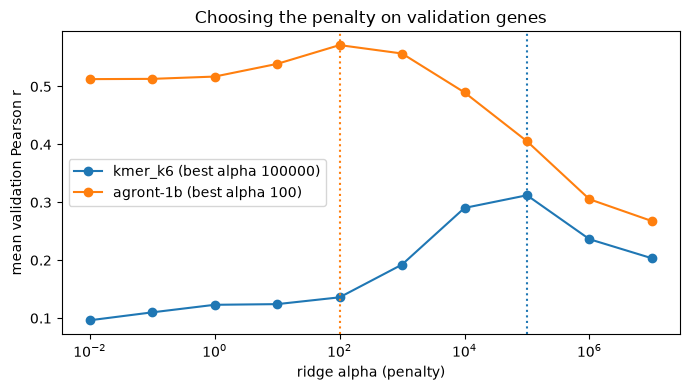

In [14]:
feature_sets = {"kmer_k6": X_kmer}
if HAVE_EMB:
    feature_sets[MODEL] = X_lm

fitted = {}
fig, ax = plt.subplots(figsize=(7, 4))
for name, X in feature_sets.items():
    t0 = time.time()
    scaler, model, sel = evaluate.fit_ridge_head(X["train"], task["train"].y, X["valid"], task["valid"].y)
    fitted[name] = (scaler, model, sel)
    alphas, scores = zip(*sorted(sel["valid_pearson_by_alpha"].items()))
    ax.plot(alphas, scores, "o-", label=f"{name} (best alpha {sel['alpha']:g})")
    ax.axvline(sel["alpha"], ls=":", color=ax.lines[-1].get_color())
    print(f"{name:10s} best alpha {sel['alpha']:>10g}  validation Pearson {max(scores):.3f}  "
          f"edge of grid: {sel['alpha_at_grid_edge']}  ({time.time() - t0:.0f} s)")
ax.set_xscale("log"); ax.set_xlabel("ridge alpha (penalty)"); ax.set_ylabel("mean validation Pearson r")
ax.set_title("Choosing the penalty on validation genes"); ax.legend(); plt.tight_layout(); plt.show()

## Step 5. Score on the test genes (used once)

**Input:** each fitted model and the 3,402 test genes it has never seen.

**Process:** predict all 56 tissues for every test gene, then compute Pearson r, Spearman ρ and R² per tissue
(`evaluate.per_output_metrics`) and average them.

**Output:** the results table, a per-tissue comparison and observed-vs-predicted plots.

In [15]:
preds, metrics = {}, {}
for name, (scaler, model, sel) in fitted.items():
    preds[name] = model.predict(scaler.transform(feature_sets[name]["test"]))
    metrics[name] = evaluate.per_output_metrics(task["test"].y, preds[name])

table = pd.DataFrame({name: m["mean"] for name, m in metrics.items()}).T.round(3)
table.columns = ["mean Pearson r", "mean Spearman rho", "mean R2"]
display(table)

,mean Pearson r,mean Spearman rho,mean R2
kmer_k6,0.346,0.339,0.088
agront-1b,0.568,0.577,0.313


AgroNT beats k-mers on 56 of 56 tissues
AgroNT lowest tissue rho = 0.449; k-mer highest tissue rho = 0.386


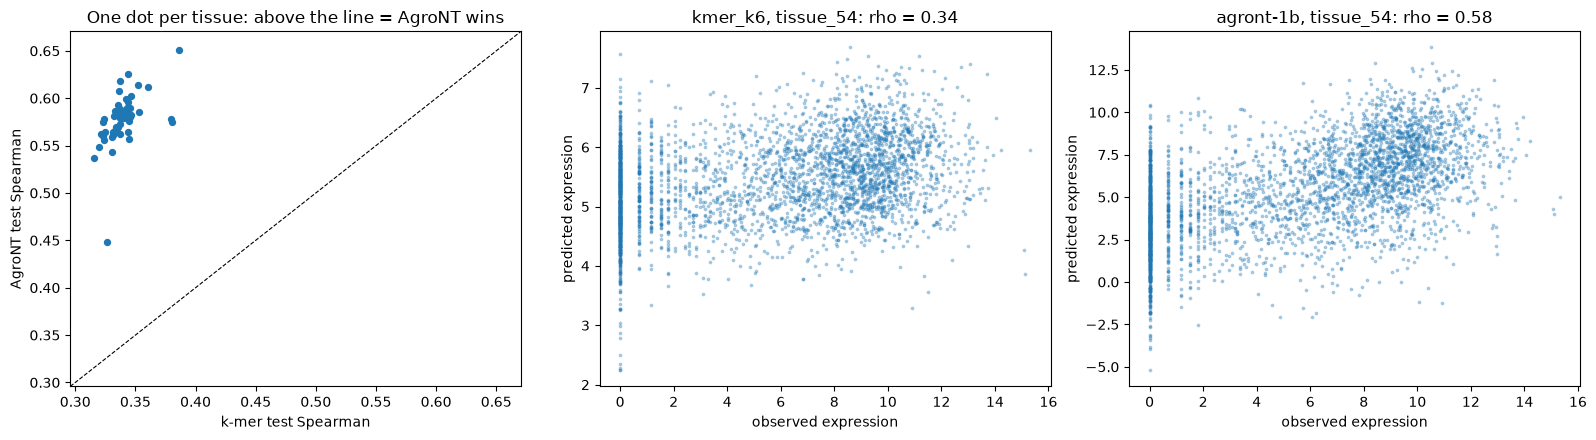

In [16]:
per_tissue = pd.DataFrame({name: [o["spearman"] for o in m["per_output"]] for name, m in metrics.items()})
per_tissue.index = [f"tissue_{j+1}" for j in range(len(per_tissue))]
per_tissue.to_csv(OUT_DIR / "per_tissue_spearman.csv")

if HAVE_EMB:
    wins = int((per_tissue[MODEL] > per_tissue["kmer_k6"]).sum())
    print(f"AgroNT beats k-mers on {wins} of {len(per_tissue)} tissues")
    print(f"AgroNT lowest tissue rho = {per_tissue[MODEL].min():.3f}; k-mer highest tissue rho = {per_tissue['kmer_k6'].max():.3f}")

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    ax[0].scatter(per_tissue["kmer_k6"], per_tissue[MODEL], s=18)
    lo, hi = per_tissue.min().min() - 0.02, per_tissue.max().max() + 0.02
    ax[0].plot([lo, hi], [lo, hi], "k--", lw=0.8); ax[0].set_xlim(lo, hi); ax[0].set_ylim(lo, hi)
    ax[0].set_xlabel("k-mer test Spearman"); ax[0].set_ylabel("AgroNT test Spearman")
    ax[0].set_title("One dot per tissue: above the line = AgroNT wins")
    j = int(per_tissue[MODEL].sub(per_tissue[MODEL].median()).abs().argmin())   # a typical tissue
    for a, name in zip(ax[1:], ["kmer_k6", MODEL]):
        a.scatter(task["test"].y[:, j], preds[name][:, j], s=3, alpha=0.3)
        a.set_xlabel("observed expression"); a.set_ylabel("predicted expression")
        a.set_title(f"{name}, tissue_{j+1}: rho = {per_tissue[name].iloc[j]:.2f}")
    plt.tight_layout(); plt.savefig(OUT_DIR / "walkthrough_comparison.png", dpi=150); plt.show()

## Step 6. How sure are we? A bootstrap confidence interval

**Input:** the test genes, their observed expression and both models' predictions.

**Process:** resample the 3,402 test genes with replacement many times; each time, recompute both models' mean
Spearman and their difference. The middle 95% of those differences is the confidence interval.

**Output:** the gain with a 95% interval. If the interval excludes 0, the gain is not a fluke of which genes ended up in the test set.

In [17]:
def mean_spearman(Y, P):
    # Spearman per column = Pearson on ranks, averaged over the 56 tissues
    R1, R2 = rankdata(Y, axis=0), rankdata(P, axis=0)
    R1 -= R1.mean(0); R2 -= R2.mean(0)
    r = (R1 * R2).sum(0) / np.sqrt((R1 ** 2).sum(0) * (R2 ** 2).sum(0))
    return np.nanmean(r)

if HAVE_EMB:
    B, rng = 300, np.random.default_rng(SEED)
    Y, n = task["test"].y, len(task["test"].y)
    diffs = []
    t0 = time.time()
    for _ in range(B):
        b = rng.integers(0, n, n)
        diffs.append(mean_spearman(Y[b], preds[MODEL][b]) - mean_spearman(Y[b], preds["kmer_k6"][b]))
    diffs = np.array(diffs)
    point = mean_spearman(Y, preds[MODEL]) - mean_spearman(Y, preds["kmer_k6"])
    low, high = np.percentile(diffs, [2.5, 97.5])
    print(f"Gain in mean Spearman (AgroNT - k-mer): {point:.3f}  95% CI [{low:.3f}, {high:.3f}]  "
          f"({B} resamples, {time.time() - t0:.0f} s)")
    json.dump({"gain": float(point), "ci95": [float(low), float(high)], "resamples": B}, open(OUT_DIR / "bootstrap_gain.json", "w"), indent=2)

Gain in mean Spearman (AgroNT - k-mer): 0.238  95% CI [0.212, 0.264]  (300 resamples, 23 s)


## Step 7. What was written to disk

In [18]:
for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1e3:.0f} kB)")
summary_csv = ROOT / "results" / "summary.csv"
if summary_csv.exists():
    print("\nThe pipeline's own results table (results/summary.csv):")
    display(pd.read_csv(summary_csv).round(3))

results\walkthrough\bootstrap_gain.json  (0 kB)
results\walkthrough\per_tissue_spearman.csv  (3 kB)
results\walkthrough\walkthrough_comparison.png  (281 kB)

The pipeline's own results table (results/summary.csv):


,model,species,n_train,n_test,n_features,alpha,mean_pearson,mean_spearman,mean_r2
0,agront-1b,arabidopsis_thaliana,5000,3402,1500,100.0,0.568,0.577,0.313
1,kmer_k6,arabidopsis_thaliana,5000,3402,4096,100000.0,0.346,0.339,0.088
2,kmer_k5,arabidopsis_thaliana,5000,3402,1024,10000.0,0.336,0.330,0.111
3,kmer_k4,arabidopsis_thaliana,5000,3402,256,1000.0,0.318,0.317,0.100
4,kmer_k6,arabidopsis_thaliana,25731,3402,4096,100000.0,0.381,0.377,0.137


## Recap

| Step | Input | Process (file) | Output |
| --- | --- | --- | --- |
| 1 Read | 3 FASTA files | `pgb.read_fasta` | IDs, 6 kb sequences, genes × 56 expression matrix |
| 2 Subset | 25,731 train genes, seed 2026 | `pgb.subsample_indices` | 5,000 / 3,401 / 3,402 genes |
| 3a k-mers | sequences | `kmers.kmer_matrix` | genes × 4,096 frequencies |
| 3b AgroNT | sequences (on Colab GPU) | `embed.embed_sequences` | genes × 1,500 embeddings |
| 4 Ridge | features + y (train, validation) | `evaluate.fit_ridge_head` | fitted model, chosen alpha |
| 5 Score | test genes | `evaluate.per_output_metrics` | Pearson, Spearman, R² per tissue |
| 6 Bootstrap | test predictions | resampling | 95% interval on the gain |